# 04 — Build the samples and the entry-time features

This notebook codes every request's outcome and clock, selects the Track A
(timing) and Track B (ever built?) samples with their train/validation/test
split, builds the features known on the request date, and checks that none of
them leaks information from after entry.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 |
| out | `data/interim/queue_events.parquet` | every clean request with outcome, clock and features |
| out | `data/interim/trackA.parquet`, `data/interim/trackB.parquet` | the two modelling samples |
| out | `results/trackA_exclusions.csv`, `results/sample_sizes.csv`, `results/feature_summary.csv` | sample flow and feature table |
| out | `results/stamp_simulation.csv`, `results/features_checks.csv` | decision #21 check; acceptance checks |
| out | `figures/04_build_features/*.png|svg`, `report/figure_notes.md` | 7 exploratory figures |

## Setup

Outcomes and samples come from `src/events.py`, features from
`src/features.py`. `MAIN_FEATURES` is the list the main models may use;
`ABLATION_FEATURES` (the ambition gap) is built but reserved for the leakage
ablation (decision #22).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, events, features, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_build_features"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_build_features/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import subprocess

from sklearn.linear_model import LogisticRegression

COHORT_COLORS = {"2000–09": "#6BAED6", "2010–14": "#2171B5", "2015–19": "#08306B"}
SPLITS = ["train", "validation", "test", "later"]

## 1. Outcomes, clock, features

Every clean request gets its outcome and duration (`events.code_events`), the
ERCOT bulk-date flag (decision #21), its split, and the entry-time features
(`features.build_features`).

In [2]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
coded = events.code_events(clean)
coded["wd_bulk_date"] = events.flag_bulk_withdrawals(coded)
coded["entry_years"] = events.delayed_entry_years(coded)
coded["split"] = events.split_label(coded["q_year"])
feature_table = features.build_features(clean)
shared = [c for c in feature_table.columns if c in coded.columns and c not in ("region", "q_year")]
queue = coded.drop(columns=shared).join(feature_table.drop(columns=["region", "q_year"]))  # feature versions win
print("Requests:", f"{len(queue):,}", "| ERCOT bulk-dated withdrawals flagged:", int(queue["wd_bulk_date"].sum()))
print("Main features:", features.MAIN_FEATURES)
print("Ablation-only features:", features.ABLATION_FEATURES)
queue["event"].map(events.EVENT_NAMES).value_counts().to_frame("requests").T

Requests: 36,216 | ERCOT bulk-dated withdrawals flagged: 441
Main features: ['region', 'state', 'type_group', 'hybrid', 'log_mw', 'size_regime', 'service', 'q_year', 'congestion_n', 'congestion_gw', 'congestion_rank']
Ablation-only features: ['ambition_gap_years', 'ambition_gap_missing']


event,censored,withdrawal,operation
requests,24042,9885,2289


**Reading this.** All 36,216 clean requests now carry an outcome — 2,289 operation, 9,885 withdrawal, 24,042 still waiting (censored) at 2024-12-31 — and a clock from their request date. Most censored rows are outside the Track A regions, where exit dates are missing, or recent entrants. The 441 ERCOT withdrawals dated 2018-08-29 are flagged in `wd_bulk_date`, and `entry_years` holds the delayed-entry time for ERCOT requests that entered before that date (section 9 explains why the main models use it).

## 2. Track A — the timing sample (CAISO, ERCOT, PJM)

PLAN.md defines the Track A candidates as the three ISOs' requests whose
status-implied exit date is present; the timing models also need a valid
request date. Every row lost on the way is counted in
`results/trackA_exclusions.csv`.

In [3]:
in_region = queue["region"].isin(TRACK_A)
candidates = in_region & ~queue["exclusion"].isin(["operational without operation date",
                                                   "withdrawn without withdrawal date"])
track_a = events.track_a_sample(queue)
exclusions = (queue[in_region & (queue["exclusion"] != "")]
              .groupby(["region", "exclusion"]).size().unstack(fill_value=0).reindex(TRACK_A).fillna(0).astype(int))
exclusions.to_csv(paths.RESULTS / "trackA_exclusions.csv")
print(f"Track A candidates (PLAN.md definition: exit date present): {int(candidates.sum()):,}")
print(f"Track A modelling sample (also a valid request date): {len(track_a):,}")
print("Completions : withdrawals =", int((track_a["event"] == 1).sum()), ":", int((track_a["event"] == 2).sum()),
      f"(1 : {(track_a['event'] == 2).sum() / (track_a['event'] == 1).sum():.1f})")
exclusions

Track A candidates (PLAN.md definition: exit date present): 13,665
Track A modelling sample (also a valid request date): 13,366
Completions : withdrawals = 1730 : 7064 (1 : 4.1)


exclusion,no valid request date,operational without operation date,withdrawn without withdrawal date
region,,,
ERCOT,268,17,0
PJM,24,23,152
CAISO,7,13,343


**Reading this.** The Track A candidates by the plan's definition number 13,665, inside the expected 13,500–14,500 (notebook 01 counted 13,733 on the raw file; cleaning removed non-generation rows). The modelling sample, which also needs a valid request date, has 13,366 requests: ERCOT loses 268 to missing request dates, CAISO 343 withdrawn rows without a withdrawal date, PJM 152. Outcomes split 1,730 completions to 7,064 withdrawals, one to 4.1, as the plan expected.

## 3. Track B — the all-regions sample

Track B asks only whether a request was ever built, so it can use all nine
regions; it keeps requests entering up to 2017 whose outcome is known
(`events.track_b_sample`).

In [4]:
track_b = events.track_b_sample(queue)
year_b = track_b["q_year"].astype(float)
track_b["split"] = np.select([year_b <= config.TUNE_MAX_YEAR, year_b == config.VALIDATION_YEAR,
                              year_b == config.TRACK_B_MAX_YEAR], ["train", "validation", "test"], "other")
print(f"Track B sample: {len(track_b):,} resolved requests entering up to {config.TRACK_B_MAX_YEAR}; "
      f"built share {track_b['built'].mean():.1%}")
pd.crosstab(track_b["region"], track_b["split"]).reindex(config.ALL_REGIONS)[["train", "validation", "test"]]

Track B sample: 14,624 resolved requests entering up to 2017; built share 22.5%


split,train,validation,test
region,,,
ERCOT,660,55,87
PJM,2929,358,303
CAISO,1246,108,74
MISO,1514,198,155
SPP,941,151,167
NYISO,431,29,67
ISO-NE,383,29,51
West,2881,286,338
Southeast,659,232,292


**Reading this.** Track B has 14,624 resolved requests from all nine regions entering up to 2017, of which 22.5% were built. Its test cohort, the 2017 entrants, holds 1,534 requests and 279 completions; every region contributes at least 51 test requests, enough for the leave-one-region-out check of notebook 07.

## 4. Sample sizes by split

Tune on entrants up to 2015, validate on 2016, refit on up to 2016 and test on
2017–2019 (Track A) or 2017 (Track B). The figure shows how many requests and
outcomes each part holds.

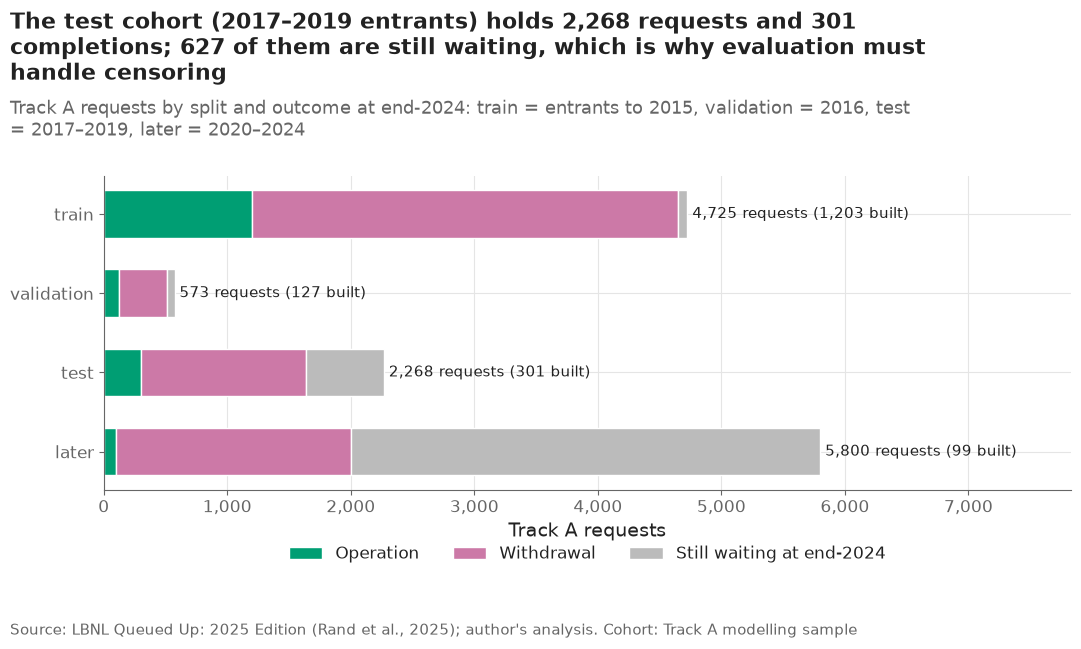

censored  operation  requests  withdrawal
track split                                                
A     later           3801         99      5800        1900
      test             627        301      2268        1340
      train             80       1203      4725        3442
      validation        64        127       573         382
B     test               0        279      1534        1255
      train              0       2748     11644        8896
      validation         0        266      1446        1180

In [5]:
size_rows = []
for split in SPLITS:
    part = track_a[track_a["split"] == split]
    for region in TRACK_A:
        piece = part[part["region"] == region]
        size_rows.append({"track": "A", "split": split, "region": region, "requests": len(piece),
                          "operation": int((piece["event"] == 1).sum()), "withdrawal": int((piece["event"] == 2).sum()),
                          "censored": int((piece["event"] == 0).sum())})
for split in ["train", "validation", "test"]:
    part = track_b[track_b["split"] == split]
    size_rows.append({"track": "B", "split": split, "region": "all nine", "requests": len(part),
                      "operation": int(part["built"].sum()), "withdrawal": int((1 - part["built"]).sum()), "censored": 0})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(paths.RESULTS / "sample_sizes.csv", index=False)

a = sizes[sizes["track"] == "A"].groupby("split")[["operation", "withdrawal", "censored"]].sum().reindex(SPLITS)
fig, ax = plt.subplots()
left = np.zeros(len(a))
for column, color in [("operation", config.OUTCOME_COLORS["operation"]),
                      ("withdrawal", config.OUTCOME_COLORS["withdrawal"]), ("censored", "#BBBBBB")]:
    ax.barh(a.index[::-1], a[column][::-1], left=left[::-1], color=color, height=0.6,
            label={"censored": "Still waiting at end-2024"}.get(column, column.capitalize()),
            edgecolor="white", linewidth=1)
    left += a[column].values
for i, (split, total) in enumerate(a.sum(axis=1)[::-1].items()):
    ax.text(total + 40, i, f"{int(total):,} requests ({int(a.loc[split, 'operation']):,} built)", va="center",
            fontsize=11)
ax.set_xlim(0, a.sum(axis=1).max() * 1.35)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.set_xlabel("Track A requests")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))
test = a.loc["test"]
plots.finish(fig,
             f"The test cohort (2017–2019 entrants) holds {int(test.sum()):,} requests and {int(test['operation'])} "
             f"completions; {int(test['censored']):,} of them are still waiting, which is why evaluation must handle censoring",
             "Track A requests by split and outcome at end-2024: train = entrants to 2015, validation = 2016, "
             "test = 2017–2019, later = 2020–2024",
             "Track A modelling sample")
save(fig, "04_01_sample_by_split", "Track A requests by temporal split and outcome at the end of 2024.")
plt.show()
sizes.pivot_table(index=["track", "split"], values=["requests", "operation", "withdrawal", "censored"], aggfunc="sum")

**Reading this.** The test cohort (2017–2019 entrants) has 2,268 requests: 301 built, 1,340 withdrawn and 627 still waiting at the end of 2024 — 28% of the cohort with no final outcome, which is why notebook 08 uses censoring-aware metrics. Training (entrants to 2015) holds 4,725 requests with 1,203 completions, validation (2016) 573 with 127. The 5,800 later entrants (2020–2024) have only 99 completions so far; they are used for nothing but the time-varying congestion that earlier projects face.

## 5. The features

One row per feature: what kind it is, how often it is missing, and its
distribution in the Track A sample; saved to `results/feature_summary.csv`.

In [6]:
summary_rows = []
for name in features.MAIN_FEATURES + features.ABLATION_FEATURES:
    column = track_a[name] if name in track_a else queue.loc[track_a.index, name]
    numeric = pd.api.types.is_numeric_dtype(column) and not pd.api.types.is_bool_dtype(column)
    summary_rows.append({
        "feature": name, "use": "main" if name in features.MAIN_FEATURES else "leakage ablation only",
        "kind": "numeric" if numeric else "categorical",
        "missing_share": round(float(column.isna().mean()), 4),
        "summary": (f"median {column.median():.2f}, IQR {column.quantile(0.25):.2f}–{column.quantile(0.75):.2f}"
                    if numeric else f"{column.nunique()} levels; most common {column.astype(str).mode()[0]} "
                    f"({(column.astype(str) == column.astype(str).mode()[0]).mean():.0%})"),
    })
feature_summary = pd.DataFrame(summary_rows)
feature_summary.to_csv(paths.RESULTS / "feature_summary.csv", index=False)
feature_summary

,feature,use,kind,missing_share,summary
0,region,main,categorical,0.0000,3 levels; most common PJM (59%)
1,state,main,categorical,0.0000,26 levels; most common TX (22%)
2,type_group,main,categorical,0.0000,14 levels; most common Solar (43%)
3,hybrid,main,categorical,0.0000,2 levels; most common False (92%)
4,log_mw,main,numeric,0.0000,"median 4.38, IQR 3.00–5.30"
5,size_regime,main,categorical,0.0000,6 levels; most common 20–<100 (31%)
6,service,main,categorical,0.0000,3 levels; most common NRIS (68%)
7,q_year,main,numeric,0.0000,"median 2019.00, IQR 2012.00–2021.00"
8,congestion_n,main,numeric,0.0000,"median 788.00, IQR 373.00–1509.00"
9,congestion_gw,main,numeric,0.0000,"median 122.07, IQR 91.79–195.93"


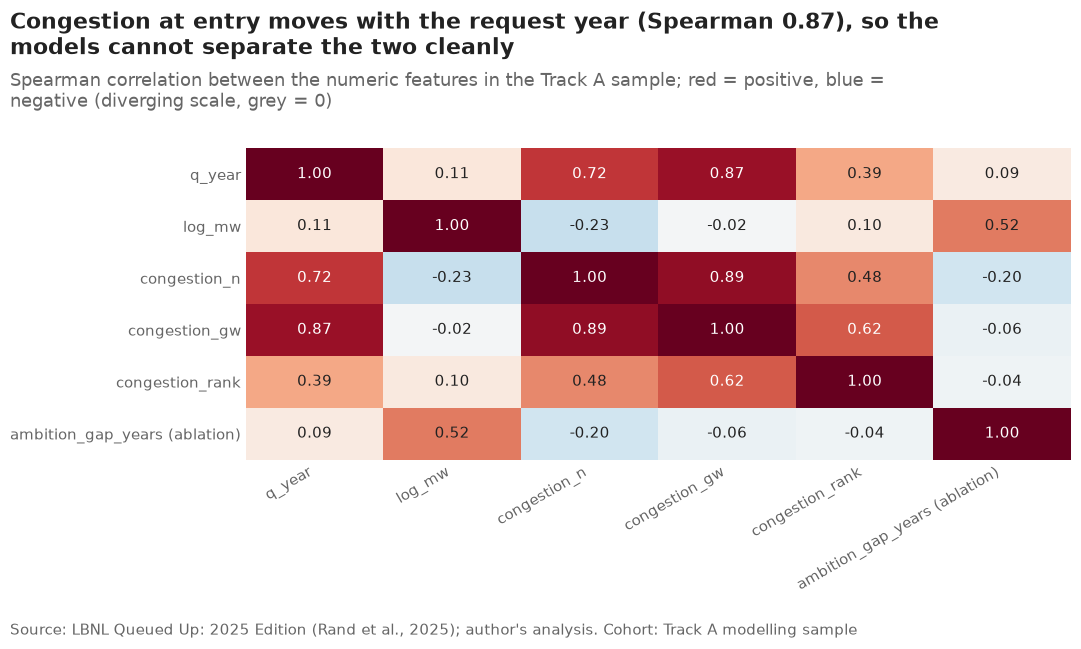

,q_year,log_mw,congestion_n,congestion_gw,congestion_rank,ambition_gap_years
q_year,1.00,0.11,0.72,0.87,0.39,0.09
log_mw,0.11,1.00,-0.23,-0.02,0.10,0.52
congestion_n,0.72,-0.23,1.00,0.89,0.48,-0.20
congestion_gw,0.87,-0.02,0.89,1.00,0.62,-0.06
congestion_rank,0.39,0.10,0.48,0.62,1.00,-0.04
ambition_gap_years,0.09,0.52,-0.20,-0.06,-0.04,1.00


In [7]:
numeric = ["q_year", "log_mw", "congestion_n", "congestion_gw", "congestion_rank", "ambition_gap_years"]
corr = track_a[numeric].astype(float).corr(method="spearman")
fig, ax = plt.subplots()
ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
labels = [n + (" (ablation)" if n in features.ABLATION_FEATURES else "") for n in numeric]
ax.set_xticks(range(len(numeric)), labels, rotation=30, ha="right", fontsize=11)
ax.set_yticks(range(len(numeric)), labels, fontsize=11)
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=11,
                color="white" if abs(corr.iat[i, j]) > 0.6 else plots.INK)
plots.finish(fig,
             f"Congestion at entry moves with the request year (Spearman {corr.loc['q_year', 'congestion_gw']:.2f}), "
             "so the models cannot separate the two cleanly",
             "Spearman correlation between the numeric features in the Track A sample; red = positive, blue = negative "
             "(diverging scale, grey = 0)",
             "Track A modelling sample")
save(fig, "04_02_feature_correlation", "Spearman correlations between the numeric entry-time features in Track A.")
plt.show()
corr.round(2)

**Reading this.** Congestion at entry is strongly tied to the request year (Spearman 0.87 for GW waiting, 0.72 for the number of requests), and the two congestion counts to each other (0.89). The relative rank is less tied to time (0.39). The stored ambition gap correlates with size (0.52): large projects propose later online dates. For the models this means congestion's effect will be estimated mostly from variation *within* entry years, and its coefficient should be read together with the year effect, not alone.

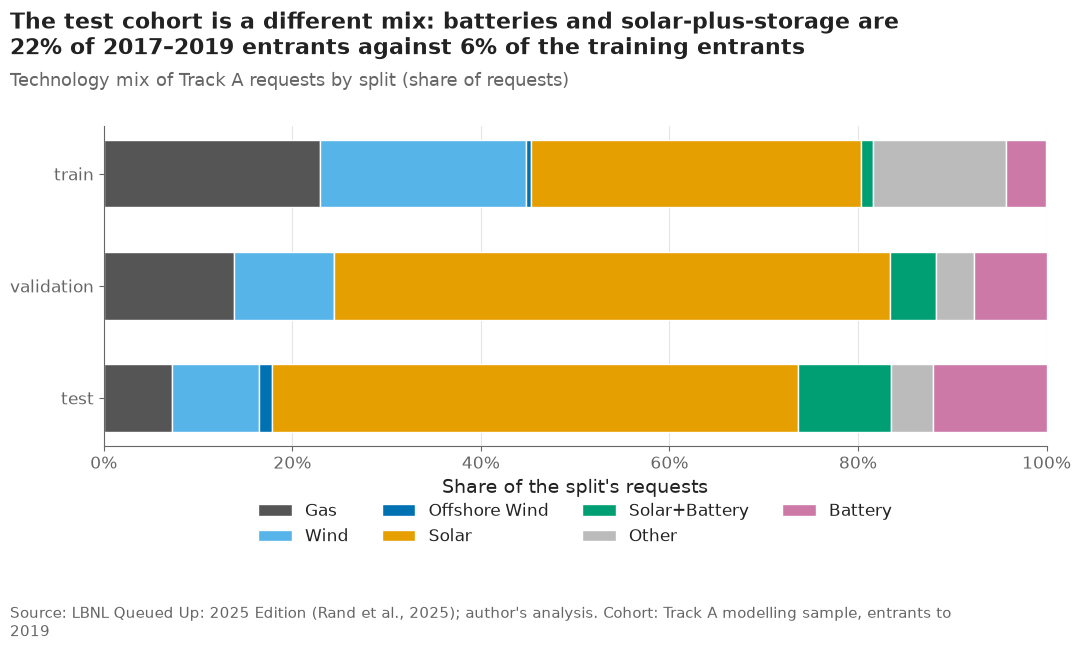

group,Solar,Solar+Battery,Wind,Offshore Wind,Battery,Gas,Other
split,,,,,,,
train,34.9,1.3,21.8,0.6,4.3,23.0,14.1
validation,59.0,4.9,10.6,0.0,7.7,13.8,4.0
test,55.8,9.9,9.2,1.4,12.0,7.3,4.5


In [8]:
mix = (track_a[track_a["split"].isin(["train", "validation", "test"])]
       .assign(group=lambda t: t["type_clean"].map(plots.tech_group))
       .pipe(lambda t: pd.crosstab(t["split"], t["group"], normalize="index"))
       .reindex(index=["train", "validation", "test"], columns=list(config.TECH_COLORS)).fillna(0))
fig, ax = plt.subplots()
left = np.zeros(len(mix))
for group in ["Gas", "Wind", "Offshore Wind", "Solar", "Solar+Battery", "Other", "Battery"]:
    ax.barh(mix.index[::-1], mix[group][::-1], left=left[::-1], color=config.TECH_COLORS[group], height=0.6,
            label=group, edgecolor="white", linewidth=1)
    left += mix[group].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of the split's requests")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.13))
storage_share = mix[["Battery", "Solar+Battery"]].sum(axis=1)
plots.finish(fig,
             f"The test cohort is a different mix: batteries and solar-plus-storage are {storage_share['test']:.0%} of "
             f"2017–2019 entrants against {storage_share['train']:.0%} of the training entrants",
             "Technology mix of Track A requests by split (share of requests)",
             "Track A modelling sample, entrants to 2019")
save(fig, "04_03_technology_mix_by_split", "Technology mix of Track A requests in the train, validation and test splits.")
plt.show()
(100 * mix).round(1)

**Reading this.** The test cohort is a different population from the training one: batteries and solar+battery hybrids are 21.9% of 2017–2019 entrants against 5.6% of training entrants, solar rises from 34.9% to 55.8%, and gas falls from 23.0% to 7.3%. A model can only learn storage outcomes from the few early storage requests, so its test performance on storage will be the weakest link; notebook 08 reports metrics by technology for that reason.

## 6. Yearly hazards: what the discrete-time models will learn

Each Track A request is expanded into one row per year in the queue
(`survival_tools.expand_project_years`); the share of requests still waiting
at the start of year k that operate or withdraw during year k is the yearly
hazard notebook 06 models.

Project-years (years 1–10): 40,509 from 13,366 requests


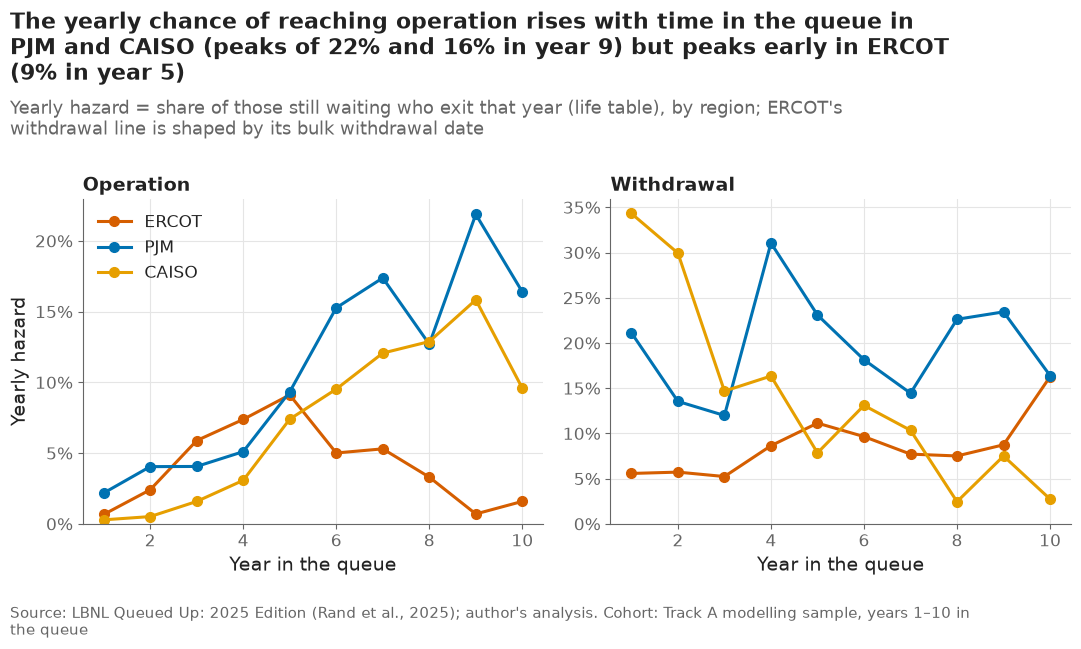

h_operation               h_withdrawal              
region              CAISO  ERCOT    PJM        CAISO  ERCOT    PJM
year_in_queue                                                     
1                   0.003  0.007  0.022        0.343  0.056  0.211
2                   0.005  0.024  0.040        0.299  0.057  0.135
3                   0.016  0.059  0.041        0.147  0.052  0.120
4                   0.031  0.074  0.051        0.163  0.086  0.311
5                   0.074  0.091  0.093        0.078  0.111  0.231
6                   0.095  0.050  0.153        0.131  0.096  0.181
7                   0.121  0.053  0.174        0.103  0.077  0.144
8                   0.129  0.033  0.127        0.025  0.075  0.226
9                   0.158  0.007  0.219        0.075  0.087  0.234
10                  0.096  0.016  0.164        0.027  0.163  0.164

In [9]:
rows = survival_tools.expand_project_years(track_a, max_years=10)
rows["region"] = track_a.loc[rows["project"], "region"].to_numpy()
life = rows.groupby(["region", "year_in_queue"])["outcome"].agg(
    at_risk="size", operation=lambda o: (o == 1).sum(), withdrawal=lambda o: (o == 2).sum()).reset_index()
life["h_operation"] = life["operation"] / life["at_risk"]
life["h_withdrawal"] = life["withdrawal"] / life["at_risk"]
print(f"Project-years (years 1–10): {len(rows):,} from {track_a.shape[0]:,} requests")

fig, axes = plt.subplots(1, 2, sharex=True)
for ax, (column, title) in zip(axes, [("h_operation", "Operation"), ("h_withdrawal", "Withdrawal")]):
    for region in TRACK_A:
        part = life[life["region"] == region]
        ax.plot(part["year_in_queue"], part[column], color=plots.region_color(region), marker="o", label=region)
    ax.set_title(title)
    ax.set_xlabel("Year in the queue")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.set_ylim(0, None)
axes[0].set_ylabel("Yearly hazard")
axes[0].legend(loc="upper left")
peak = life.loc[life.groupby("region")["h_operation"].idxmax()].set_index("region")
plots.finish(fig,
             "The yearly chance of reaching operation rises with time in the queue in PJM and CAISO (peaks of "
             f"{peak.loc['PJM', 'h_operation']:.0%} and {peak.loc['CAISO', 'h_operation']:.0%} in year "
             f"{int(peak.loc['PJM', 'year_in_queue'])}) but peaks early in ERCOT ({peak.loc['ERCOT', 'h_operation']:.0%} "
             f"in year {int(peak.loc['ERCOT', 'year_in_queue'])})",
             "Yearly hazard = share of those still waiting who exit that year (life table), by region; ERCOT's withdrawal line is shaped by its "
             "bulk withdrawal date",
             "Track A modelling sample, years 1–10 in the queue")
save(fig, "04_04_yearly_hazards", "Yearly hazards of operation and withdrawal by year in the queue for CAISO, ERCOT and PJM.")
plt.show()
life.pivot_table(index="year_in_queue", columns="region", values=["h_operation", "h_withdrawal"]).round(3)

**Reading this.** The life table shows what a discrete-time model has to capture. In PJM and CAISO the yearly chance of reaching operation keeps rising for years (PJM 2.2% in year 1, 15.3% in year 6, 21.9% in year 9), so projects that survive a long wait become more likely to finish, not less. ERCOT peaks early (9.1% in year 5) and falls after, which may partly reflect the bulk withdrawal date keeping long-gone projects in its risk set. Withdrawal is front-loaded in CAISO (34.3% of waiting projects leave in year 1) and has a spike in PJM's year 4 (31.1%), consistent with study-phase deadlines. These shapes are far from smooth, which is why notebook 06 gives every year in the queue its own effect. The values beyond year 7 rest on fewer projects.

## 7. Why the proposed online date is kept out (decision #22)

Notebook 01 showed that the stored proposed online date often equals the
actual one. If it were an honest entry-time proposal, its gap to the request
date would say something about ambition; if it is updated later, it carries
the outcome. The figure shows how strongly it "predicts" completion.

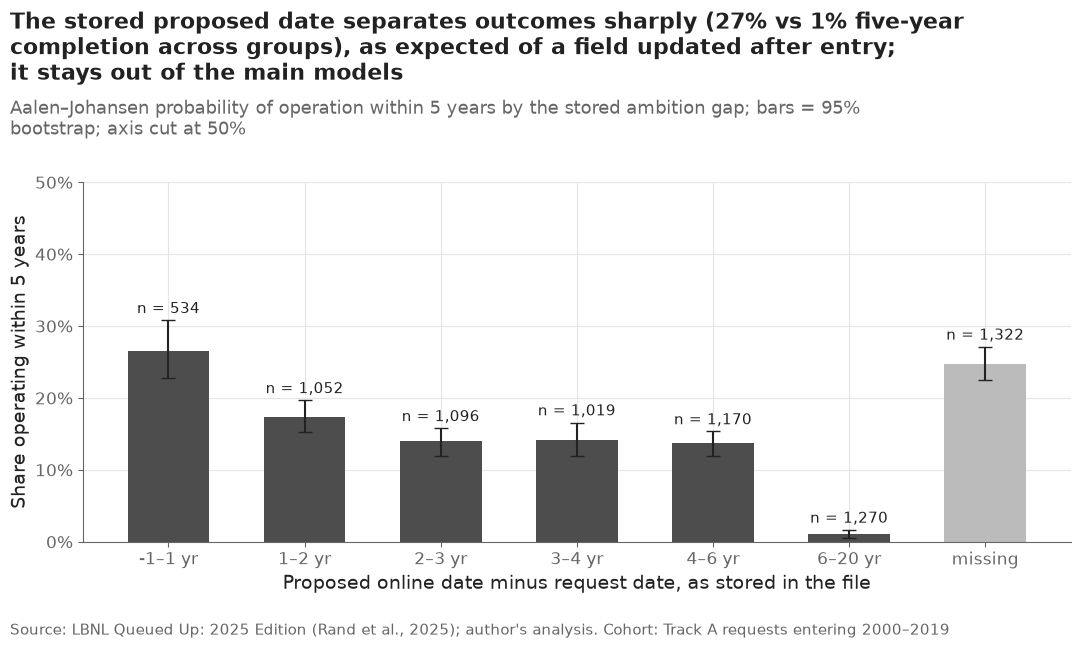

,gap,n,p5,low,high
0,-1–1 yr,534,0.266,0.228,0.308
1,1–2 yr,1052,0.174,0.153,0.197
2,2–3 yr,1096,0.140,0.119,0.158
3,3–4 yr,1019,0.141,0.119,0.166
4,4–6 yr,1170,0.137,0.119,0.153
5,6–20 yr,1270,0.010,0.005,0.017
6,missing,1322,0.247,0.225,0.271


In [10]:
early = track_a[track_a["q_year"].between(2000, 2019)]
gap_rows = []
binned = pd.cut(early["ambition_gap_years"], bins=[-1, 1, 2, 3, 4, 6, 20], include_lowest=True)
for i, (interval, part) in enumerate(early.groupby(binned, observed=True)):
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], [5.0])
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], [5.0], n_boot=500, seed=40 + i)
    gap_rows.append({"gap": f"{interval.left:.0f}–{interval.right:.0f} yr", "n": len(part),
                     "p5": fit["cif_operation"].iloc[0], "low": band["cif_operation_low"].iloc[0],
                     "high": band["cif_operation_high"].iloc[0]})
missing = early[early["ambition_gap_missing"]]
fit = survival_tools.aalen_johansen(missing["duration_years"], missing["event"], [5.0])
band = survival_tools.bootstrap_bands(missing["duration_years"], missing["event"], [5.0], n_boot=500, seed=49)
gap_rows.append({"gap": "missing", "n": len(missing), "p5": fit["cif_operation"].iloc[0],
                 "low": band["cif_operation_low"].iloc[0], "high": band["cif_operation_high"].iloc[0]})
by_gap = pd.DataFrame(gap_rows)

fig, ax = plt.subplots()
x = np.arange(len(by_gap))
ax.bar(x, by_gap["p5"], color=["#4D4D4D"] * (len(by_gap) - 1) + ["#BBBBBB"], width=0.6)
ax.errorbar(x, by_gap["p5"], yerr=[by_gap["p5"] - by_gap["low"], by_gap["high"] - by_gap["p5"]],
            fmt="none", color=plots.INK, capsize=5, linewidth=1.5)
for xi, row in zip(x, by_gap.itertuples()):
    ax.text(xi, row.high + 0.01, f"n = {row.n:,}", ha="center", fontsize=11)
ax.set_xticks(x, by_gap["gap"])
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Proposed online date minus request date, as stored in the file")
ax.set_ylabel("Share operating within 5 years")
plots.finish(fig,
             f"The stored proposed date separates outcomes sharply ({by_gap['p5'].max():.0%} vs {by_gap['p5'].min():.0%} "
             "five-year completion across groups), as expected of a field updated after entry; it stays out of the "
             "main models",
             "Aalen–Johansen probability of operation within 5 years by the stored ambition gap; bars = 95% bootstrap; "
             "axis cut at 50%",
             "Track A requests entering 2000–2019")
save(fig, "04_05_ambition_gap_leakage",
     "Five-year completion by the gap between the stored proposed online date and the request date (leakage illustration).")
plt.show()
by_gap.round(3)

**Reading this.** Five-year completion falls from 26.6% for requests whose stored proposed date is within a year of the request to 1.0% for gaps of 6–20 years — a 27-fold spread that no other single feature comes close to. Requests with no proposed date complete at 24.7%. A plan stated at entry could carry some signal, but notebook 01 showed the stored date sits within a month of the actual operation date for 44% of completed projects, so much of this spread is the outcome written back into the field. It is exactly the kind of feature that would make the models look excellent on paper and fail in use, so it stays in the leakage ablation only (decision #22).

## 8. Does a bulk withdrawal date bias P(operation by t)? (decision #21)

ERCOT's 441 bulk-dated withdrawals are kept as recorded in the main models.
The claim behind that choice is that misdating withdrawals hardly moves the
probability of *operation* by a horizon. It is tested on PJM, whose dates are
trustworthy: PJM's withdrawals are re-dated the way ERCOT's were (every
withdrawal before a cut-off date is moved to that date, with the cut-off chosen
so the same 46% of withdrawals is affected), and two estimates are compared on
the original and the stamped data — the Aalen–Johansen curve, and a simple
discrete-time multinomial logit like the one in notebook 06.

In [11]:
pjm = track_a[(track_a["region"] == "PJM") & track_a["q_year"].between(2000, 2019)].copy()
withdrawn_dates = pjm.loc[pjm["event"] == 2, "exit_date"]
ercot_share = queue["wd_bulk_date"].sum() / ((queue["region"] == "ERCOT") & (queue["event"] == 2)).sum()
cutoff = withdrawn_dates.quantile(ercot_share)
stamped = pjm.copy()
moved = (stamped["event"] == 2) & (stamped["exit_date"] < cutoff)
stamped.loc[moved, "exit_date"] = cutoff
stamped["duration_years"] = (stamped["exit_date"] - stamped["q_date"]).dt.days.clip(lower=1) / config.DAYS_PER_YEAR
print(f"Cut-off {cutoff.date()}: {int(moved.sum()):,} of {int((pjm['event'] == 2).sum()):,} PJM withdrawals re-dated "
      f"({moved.sum() / (pjm['event'] == 2).sum():.0%}; ERCOT's stamp covers {ercot_share:.0%})")


def hazard_logit_cif(train_frame, target, columns, horizons, entry=None):
    """Discrete-time multinomial logit on project-years; P(operation/withdrawal by each horizon) for `target`.

    The design is a free effect for each year in the queue (1–10) plus `columns` (categorical, or q_year as a
    number). With `entry`, project-years that end before a project's entry time are dropped (delayed entry).
    """
    rows = survival_tools.expand_project_years(train_frame, max_years=10)
    if entry is not None:
        rows = rows[rows["year_in_queue"].to_numpy() > entry.loc[rows["project"]].to_numpy()]

    def design(frame, projects, years):
        parts = {"year": np.minimum(years, 10).astype(str)}
        for column in columns:
            if column != "q_year":
                parts[column] = frame.loc[projects, column].astype(str).to_numpy()
        table = pd.get_dummies(pd.DataFrame(parts), dtype=float)
        if "q_year" in columns:
            table["q_year"] = (frame.loc[projects, "q_year"].to_numpy(dtype=float) - 2010) / 10
        return table

    train_x = design(train_frame, rows["project"], rows["year_in_queue"].to_numpy())
    model = LogisticRegression(max_iter=3000, C=5.0).fit(train_x, rows["outcome"])
    k = max(horizons)
    grid = design(target, np.repeat(target.index.to_numpy(), k), np.tile(np.arange(1, k + 1), len(target)))
    probs = model.predict_proba(grid.reindex(columns=train_x.columns, fill_value=0.0))
    classes = list(model.classes_)
    h_op = probs[:, classes.index(1)].reshape(len(target), k)
    h_wd = probs[:, classes.index(2)].reshape(len(target), k)
    cif_op, cif_wd = survival_tools.cif_from_hazards(h_op, h_wd)
    columns_out = [h - 1 for h in horizons]
    return (pd.DataFrame(cif_op[:, columns_out], index=target.index, columns=horizons),
            pd.DataFrame(cif_wd[:, columns_out], index=target.index, columns=horizons))


sim_rows = []
for label, frame in [("original", pjm), ("stamped", stamped)]:
    frame["cohort"] = events.entry_cohort(frame["q_year"]).astype(str)
    model_op, model_wd = hazard_logit_cif(frame, frame, ["cohort", "type_group"], config.HORIZONS)
    model = pd.concat([model_op.add_prefix("op_"), model_wd.add_prefix("wd_")], axis=1).groupby(frame["cohort"]).mean()
    for cohort, part in frame.groupby("cohort", observed=True):
        fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], config.HORIZONS)
        for h, op, wd in zip(config.HORIZONS, fit["cif_operation"], fit["cif_withdrawal"]):
            sim_rows.append({"data": label, "cohort": str(cohort), "horizon": h, "method": "Aalen–Johansen",
                             "operation": op, "withdrawal": wd})
            sim_rows.append({"data": label, "cohort": str(cohort), "horizon": h, "method": "discrete-time logit",
                             "operation": model.loc[str(cohort), f"op_{h}"], "withdrawal": model.loc[str(cohort), f"wd_{h}"]})
simulation = pd.DataFrame(sim_rows)
compare = simulation.pivot_table(index=["method", "cohort", "horizon"], columns="data", values=["operation", "withdrawal"])
compare[("operation", "change_points")] = 100 * (compare[("operation", "stamped")] - compare[("operation", "original")])
compare[("withdrawal", "change_points")] = 100 * (compare[("withdrawal", "stamped")] - compare[("withdrawal", "original")])
compare.to_csv(paths.RESULTS / "stamp_simulation.csv")
print("Largest change in P(operation by t), points:", round(compare[("operation", "change_points")].abs().max(), 2))
print("Largest change in P(withdrawal by t), points:", round(compare[("withdrawal", "change_points")].abs().max(), 2))
compare.round(3)

Cut-off 2015-03-17: 1,435 of 3,065 PJM withdrawals re-dated (47%; ERCOT's stamp covers 47%)


Largest change in P(operation by t), points: 6.57
Largest change in P(withdrawal by t), points: 53.39


operation         withdrawal             operation    withdrawal
data                                 original stamped   original stamped change_points change_points
method              cohort  horizon                                                                 
Aalen–Johansen      2000–09 3           0.207   0.207      0.434   0.000         0.000       -43.448
                            5           0.279   0.279      0.534   0.000         0.000       -53.386
                            7           0.317   0.317      0.585   0.192         0.000       -39.314
                    2010–14 3           0.122   0.122      0.585   0.167         0.000       -41.864
                            5           0.185   0.185      0.685   0.651         0.000        -3.397
                            7           0.228   0.228      0.726   0.726         0.000        -0.000
                    2015–19 3           0.069   0.069      0.474   0.474         0.000         0.000
                            5           0.116   0.116      0.585   0.585         0.000         0.000
                            7           0.186   0.186      0.647   0.647         0.000         0.000
discrete-time logit 2000–09 3           0.173   0.111      0.453   0.070        -6.238       -38.366
                            5           0.254   0.188      0.542   0.148        -6.571       -39.462
                            7           0.317   0.280      0.592   0.245        -3.721       -34.753
                    2010–14 3           0.122   0.129      0.584   0.331         0.689       -25.379
                            5           0.175   0.186      0.684   0.548         1.082       -13.610
                            7           0.214   0.221      0.733   0.689         0.668        -4.445
                    2015–19 3           0.085   0.116      0.465   0.341         3.137       -12.400
                            5           0.138   0.169      0.581   0.565         3.108        -1.682
                            7           0.194   0.202      0.660   0.708         0.769         4.849

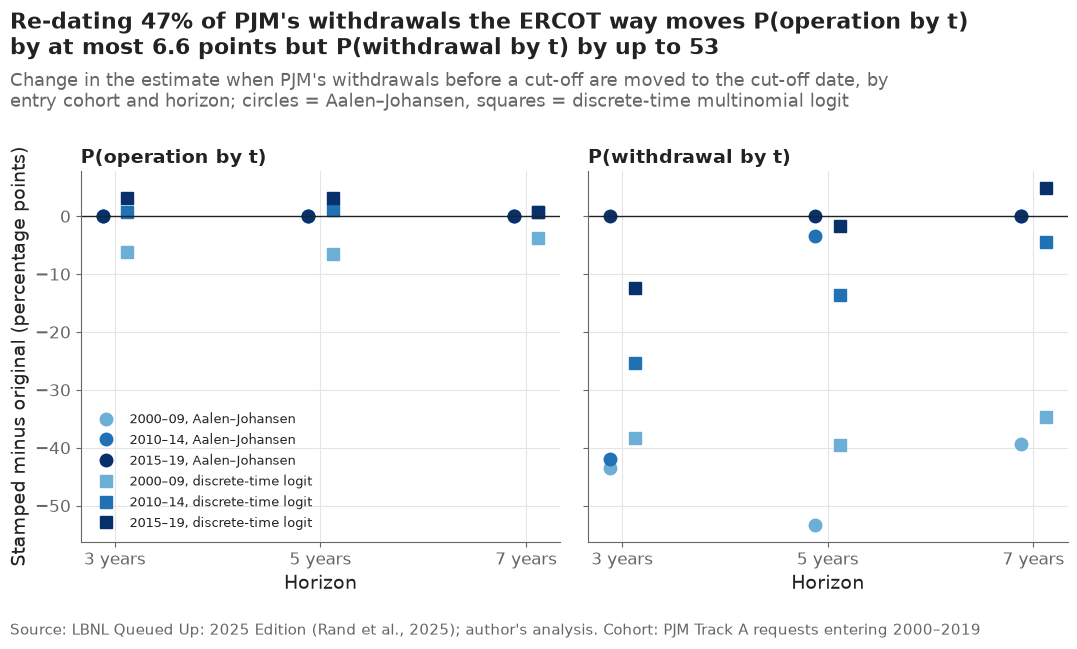

In [12]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (column, title) in zip(axes, [("operation", "P(operation by t)"), ("withdrawal", "P(withdrawal by t)")]):
    points = compare[(column, "change_points")].reset_index()
    points.columns = ["method", "cohort", "horizon", "change"]
    for (method, marker), offset in zip([("Aalen–Johansen", "o"), ("discrete-time logit", "s")], [-0.12, 0.12]):
        for cohort, color in COHORT_COLORS.items():
            part = points[(points["method"] == method) & (points["cohort"] == cohort)]
            ax.plot(part["horizon"] + offset, part["change"], marker=marker, color=color, linestyle="none",
                    markersize=9, label=f"{cohort}, {method}" if column == "operation" else None)
    ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_title(title)
    ax.set_xticks(config.HORIZONS, [f"{h} years" for h in config.HORIZONS])
    ax.set_xlabel("Horizon")
axes[0].set_ylabel("Stamped minus original (percentage points)")
axes[0].legend(loc="lower left", fontsize=9.5)
plots.finish(fig,
             f"Re-dating {moved.sum() / (pjm['event'] == 2).sum():.0%} of PJM's withdrawals the ERCOT way moves "
             f"P(operation by t) by at most {compare[('operation', 'change_points')].abs().max():.1f} points but "
             f"P(withdrawal by t) by up to {compare[('withdrawal', 'change_points')].abs().max():.0f}",
             "Change in the estimate when PJM's withdrawals before a cut-off are moved to the cut-off date, by entry cohort "
             "and horizon; circles = Aalen–Johansen, squares = discrete-time multinomial logit",
             "PJM Track A requests entering 2000–2019")
save(fig, "04_06_stamp_simulation",
     "Change in estimated P(operation by t) and P(withdrawal by t) when PJM's withdrawal dates are bulk-stamped the "
     "way ERCOT's are, by cohort, horizon and method.")
plt.show()

**Reading this.** Stamping PJM the ERCOT way — moving every withdrawal before 2015-03-17 to that date, which re-dates 1,435 of 3,065 withdrawals (47%, the same share as ERCOT) — leaves the Aalen–Johansen estimate of P(operation by t) exactly unchanged, as expected: it counts who was built and when, and the stamped projects were never built. But the discrete-time logit moves by up to 6.6 points: the stamped projects now look like they waited years before failing, which shifts the shared year-in-queue effects and with them every prediction. P(withdrawal by t) moves by up to 53 points under both. So my first argument for keeping ERCOT's dates as recorded — that the target is insensitive to them — holds for the non-parametric curves but not for the models, and the treatment of the stamped rows has to be chosen on evidence (next section).

## 9. Choosing the ERCOT treatment on the validation cohort

The simulation shows that a regression model *is* moved by stamped dates, so
the treatment of ERCOT's 441 stamped withdrawals matters for the models. Three
treatments are compared the legitimate way — fit on entrants up to 2015,
predict the 2016 entrants, compare with what happened — using the same simple
discrete-time logit:

- **(a) as recorded**: stamped withdrawals stay at 2018-08-29;
- **(b) delayed entry**: ERCOT projects enter the risk set on 2018-08-29;
  those that had already left drop out (decision #21 as approved);
- **(c) imputed**: each stamped withdrawal gets a time drawn from PJM and CAISO
  withdrawals of the same entry year that happened before the stamp.

Under (b) the model never sees an ERCOT project in its first years; it borrows
that part of the duration curve from the other two regions through a shared
year-in-queue effect plus a region shift.

In [13]:
train_val = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR].copy()
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR].copy()

treatments = {"(a) as recorded": (train_val, None)}
keep_b = train_val["duration_years"] > train_val["entry_years"]
treatments["(b) delayed entry"] = (train_val[keep_b], train_val.loc[keep_b, "entry_years"])
rng = np.random.default_rng(2026)
imputed = train_val.copy()
donors = track_a[track_a["region"].isin(["PJM", "CAISO"]) & (track_a["event"] == 2)]
for i in imputed.index[imputed["wd_bulk_date"]]:
    cap = imputed.at[i, "duration_years"]
    pool = donors.loc[(donors["q_year"] == imputed.at[i, "q_year"]) & (donors["duration_years"] <= cap), "duration_years"]
    if pool.empty:
        pool = donors.loc[donors["duration_years"] <= cap, "duration_years"]
    imputed.at[i, "duration_years"] = rng.choice(pool.to_numpy())
treatments["(c) imputed"] = (imputed, None)
print("ERCOT training requests used under delayed entry:", int(keep_b[train_val["region"] == "ERCOT"].sum()),
      "of", int((train_val["region"] == "ERCOT").sum()))

choice_rows = []
for name, (frame, entry) in treatments.items():
    predicted = hazard_logit_cif(frame, valid, ["region", "type_group", "q_year"], config.HORIZONS, entry=entry)[0]
    for region in TRACK_A:
        part = valid[valid["region"] == region]
        for h in config.HORIZONS:
            choice_rows.append({"treatment": name, "region": region, "horizon": h, "n": len(part),
                                "predicted": predicted.loc[part.index, h].mean()})
choice = pd.DataFrame(choice_rows)
observed_rows = []
for i, region in enumerate(TRACK_A):
    part = valid[valid["region"] == region]
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], config.HORIZONS)
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], config.HORIZONS, n_boot=500, seed=60 + i)
    for h, obs, low, high in zip(config.HORIZONS, fit["cif_operation"], band["cif_operation_low"], band["cif_operation_high"]):
        observed_rows.append({"region": region, "horizon": h, "observed": obs, "low": low, "high": high})
observed = pd.DataFrame(observed_rows)
choice = choice.merge(observed, on=["region", "horizon"])
choice["abs_error_points"] = 100 * (choice["predicted"] - choice["observed"]).abs()
choice.to_csv(paths.RESULTS / "ercot_treatment_validation.csv", index=False)
print("Mean absolute error over regions and horizons (points):",
      choice.groupby("treatment")["abs_error_points"].mean().round(2).to_dict())
choice.pivot_table(index=["region", "treatment"], columns="horizon", values="abs_error_points").assign(
    mean=lambda t: t.mean(axis=1)).round(1)

ERCOT training requests used under delayed entry: 80 of 666


Mean absolute error over regions and horizons (points): {'(a) as recorded': 3.43, '(b) delayed entry': 2.79, '(c) imputed': 3.05}


horizon                     3    5    7  mean
region treatment                             
CAISO  (a) as recorded    2.5  5.0  6.2   4.6
       (b) delayed entry  1.8  4.1  5.6   3.8
       (c) imputed        2.1  4.6  6.1   4.3
ERCOT  (a) as recorded    2.3  3.1  3.8   3.1
       (b) delayed entry  5.7  0.5  0.9   2.4
       (c) imputed        6.2  0.5  2.7   3.1
PJM    (a) as recorded    2.3  1.1  4.4   2.6
       (b) delayed entry  1.6  1.4  3.4   2.1
       (c) imputed        1.9  0.7  2.7   1.8

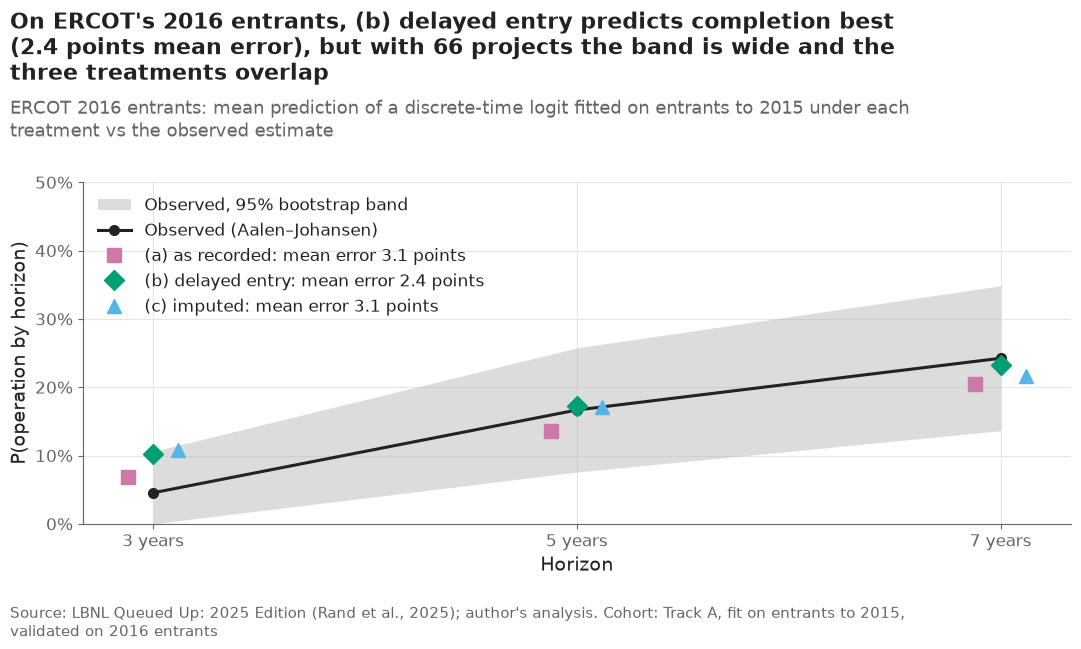

In [14]:
ercot = choice[choice["region"] == "ERCOT"]
fig, ax = plt.subplots()
obs = observed[observed["region"] == "ERCOT"]
ax.fill_between(obs["horizon"], obs["low"], obs["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                label="Observed, 95% bootstrap band")
ax.plot(obs["horizon"], obs["observed"], color=plots.INK, marker="o", label="Observed (Aalen–Johansen)")
for (name, marker, color), offset in zip([("(a) as recorded", "s", "#CC79A7"), ("(b) delayed entry", "D", "#009E73"),
                                          ("(c) imputed", "^", "#56B4E9")], [-0.12, 0, 0.12]):
    part = ercot[ercot["treatment"] == name]
    ax.plot(part["horizon"] + offset, part["predicted"], marker=marker, color=color, linestyle="none", markersize=10,
            label=f"{name}: mean error {part['abs_error_points'].mean():.1f} points")
ax.set_xticks(config.HORIZONS, [f"{h} years" for h in config.HORIZONS])
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Horizon")
ax.set_ylabel("P(operation by horizon)")
ax.legend(loc="upper left")
best = ercot.groupby("treatment")["abs_error_points"].mean().idxmin()
plots.finish(fig,
             f"On ERCOT's 2016 entrants, {best} predicts completion best "
             f"({ercot.groupby('treatment')['abs_error_points'].mean().min():.1f} points mean error), but with "
             f"{int(ercot['n'].iloc[0])} projects the band is wide and the three treatments overlap",
             "ERCOT 2016 entrants: mean prediction of a discrete-time logit fitted on entrants to 2015 under each "
             "treatment vs the observed estimate",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "04_08_ercot_treatment_validation",
     "Predicted versus observed P(operation by 3, 5 and 7 years) for ERCOT 2016 entrants under three treatments "
     "of the bulk-dated withdrawals.")
plt.show()

**Reading this.** Fitted on entrants to 2015 and checked on the 2016 entrants, delayed entry predicts best on average: mean absolute error 2.4 points for ERCOT against 3.1 as recorded and 3.1 imputed, and it is also the best or near-best for PJM (2.1) and CAISO (3.8). It errs most at three years for ERCOT (5.7 points), where it relies on the other regions' early hazards, and least at five and seven years. The validation cohort is small (66 ERCOT projects) and the three treatments all fall inside the observed band, so the evidence is modest — but it points the same way as the statistical argument (delayed entry is the only treatment that does not invent withdrawal times) and as Alan's choice. **Decision #21: the main timing models use delayed entry for ERCOT; the as-recorded version is the sensitivity run in notebook 08.**

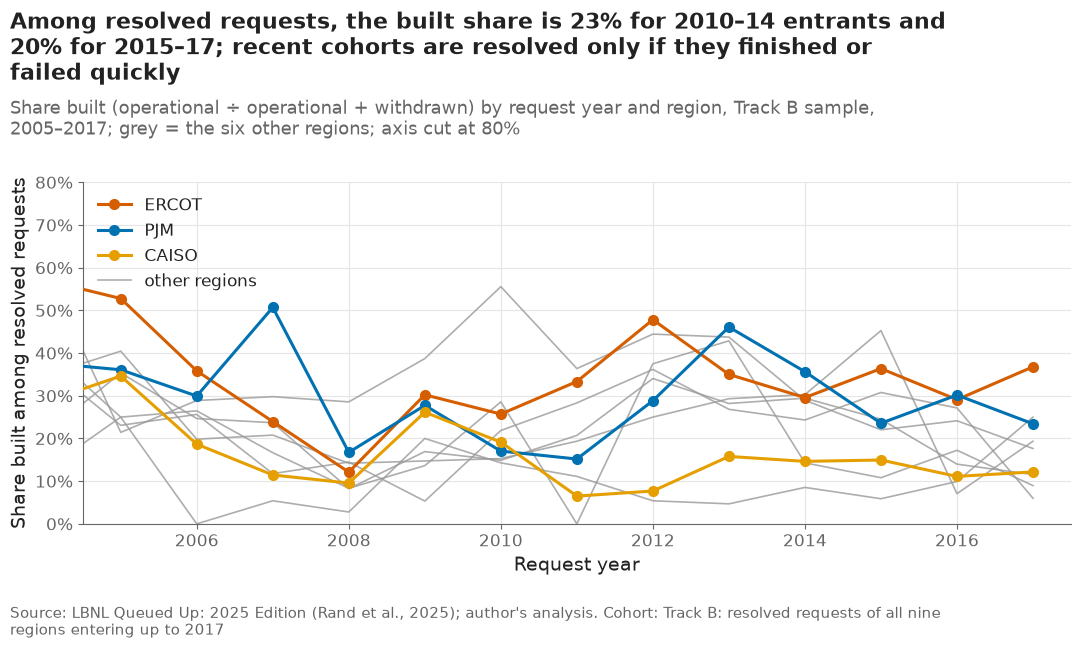

q_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
region,,,,,,,,,,,,,
ERCOT,52.8,35.8,24.0,12.1,30.2,25.7,33.3,47.8,35.0,29.6,36.4,29.1,36.8
PJM,36.1,29.9,50.7,16.7,27.7,17.0,15.2,28.8,46.1,35.6,23.6,30.2,23.4
CAISO,34.6,18.7,11.5,9.6,26.2,19.1,6.5,7.7,15.8,14.6,15.0,11.1,12.2
MISO,40.4,19.8,20.8,14.2,14.7,15.3,19.4,25.0,29.3,30.3,45.3,7.1,19.4
SPP,23.1,25.6,11.8,14.5,5.3,21.9,28.3,36.2,26.8,24.3,30.8,27.2,6.0
NYISO,25.0,26.5,16.7,8.3,13.6,28.6,0.0,37.5,42.9,14.3,10.8,17.2,9.0
ISO-NE,21.4,28.9,29.8,28.6,38.7,55.6,36.4,44.4,43.8,28.9,22.0,24.1,17.6
West,35.3,24.7,23.7,8.2,16.9,14.9,20.7,34.0,28.2,29.4,24.5,14.0,11.5
Southeast,25.0,0.0,5.4,2.8,20.0,14.3,11.1,5.4,4.7,8.5,5.9,9.9,25.0


In [15]:
built = (track_b.groupby(["q_year", "region"])["built"].mean().unstack().reindex(columns=config.ALL_REGIONS))
fig, ax = plt.subplots()
for region in config.ALL_REGIONS:
    if region in TRACK_A:
        ax.plot(built.index, built[region], color=plots.region_color(region), marker="o", label=region, zorder=3)
    else:
        ax.plot(built.index, built[region], color=config.OTHER_REGION_COLOR, linewidth=1.2, alpha=0.8,
                label="other regions" if region == "MISO" else None)
ax.set_xlim(2004.5, config.TRACK_B_MAX_YEAR + 0.5)  # earlier years hold a handful of requests per region
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share built among resolved requests")
ax.legend(loc="upper left")
late = track_b[track_b["q_year"].between(2015, 2017)]["built"].mean()
mid = track_b[track_b["q_year"].between(2010, 2014)]["built"].mean()
plots.finish(fig,
             f"Among resolved requests, the built share is {mid:.0%} for 2010–14 entrants and {late:.0%} for 2015–17; "
             "recent cohorts are resolved only if they finished or failed quickly",
             "Share built (operational ÷ operational + withdrawn) by request year and region, Track B sample, "
             "2005–2017; grey = the six other regions; axis cut at 80%",
             f"Track B: resolved requests of all nine regions entering up to {config.TRACK_B_MAX_YEAR}")
save(fig, "04_07_track_b_built_share", "Share of resolved requests that were built, by request year and region (Track B).")
plt.show()
(100 * built.loc[2005:]).round(1).T

**Reading this.** Among resolved requests, the built share was 23% for 2010–14 entrants and 20% for 2015–17 entrants; by region and year it swings from 0% (Southeast 2006, NYISO 2011) to 55.6% (ISO-NE 2010) with no steady trend. The flat look hides a selection: for recent cohorts only the projects that finished or failed quickly are resolved, so Track B's recent built shares are not comparable with older ones. That is why Track B stops at the 2017 entrants and why its results are framed as "ever built" among resolved requests.

## 10. Save the samples and run the checks

Text columns are stored as text (parquet cannot hold mixed types). Then the
acceptance checks of PLAN.md §6 (notebook 04).

In [16]:
def to_parquet(frame, name):
    """Save with object columns as text."""
    text = [c for c in frame.columns if frame[c].dtype == object]
    frame.astype({c: "string" for c in text}).to_parquet(paths.DATA_INTERIM / name)


to_parquet(queue, "queue_events.parquet")
to_parquet(track_a, "trackA.parquet")
to_parquet(track_b, "trackB.parquet")

test_run = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_features.py"], cwd=paths.REPO,
                          capture_output=True, text=True)
ratio = (track_a["event"] == 2).sum() / (track_a["event"] == 1).sum()
checks = pd.DataFrame([
    ("tests/test_features.py passes (hand-counted congestion, no post-entry information)", test_run.returncode == 0),
    ("no main feature is built from a post-entry column",
     not set(features.MAIN_FEATURES) & set(features.POST_ENTRY_COLUMNS)),
    ("no non-positive durations in Track A", bool((track_a["duration_years"] > 0).all())),
    (f"Track A candidates within {config.TRACK_A_RANGE[0]:,}–{config.TRACK_A_RANGE[1]:,} (PLAN.md definition)",
     config.TRACK_A_RANGE[0] <= int(candidates.sum()) <= config.TRACK_A_RANGE[1]),
    ("roughly one completion per four withdrawals (between 1:3 and 1:5)", 3 <= ratio <= 5),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "features_checks.csv", index=False)
print(test_run.stdout.strip().splitlines()[-1])
checks[["check", "result"]]

9 passed in 0.51s


,check,result
0,tests/test_features.py passes (hand-counted co...,PASS
1,no main feature is built from a post-entry column,PASS
2,no non-positive durations in Track A,PASS
3,"Track A candidates within 13,500–14,500 (PLAN....",PASS
4,roughly one completion per four withdrawals (b...,PASS


**Reading this.** All five checks pass: `tests/test_features.py` (9 tests, including a hand count of congestion, a test that the latest entrant's outcome cannot change any feature, and the same-day rule of the congestion rank), no main feature built from a post-entry field, no non-positive durations, 13,665 Track A candidates inside the expected range, and one completion per 4.1 withdrawals.

## Takeaways

- Samples: Track A 13,366 requests (1,730 completions, 7,064 withdrawals); Track B 14,624 resolved requests from all nine regions; test cohort 2,268 requests with 301 completions and 627 still waiting.
- Features known at entry: region, state, technology group (14 levels), hybrid, log size of the first component, size regime, service, request year, and congestion at entry (count, GW, rank). The stored ambition gap separates outcomes 27-fold, consistent with a field updated after entry; it is reserved for the leakage ablation.
- The test cohort is a different mix (22% storage against 6% in training) and congestion is strongly tied to entry year (Spearman 0.87); both are caveats for interpreting the models.
- ERCOT's bulk withdrawal date does bias regression models (up to 6.6 points in a simulation on PJM). On the 2016 validation cohort delayed entry predicted best, so the main models use it (decision #21) and the as-recorded data become the sensitivity run.

**What goes to the report:** 04_01 (sample and censoring) in the evaluation section; one sentence and 04_05 for the leakage control; 04_06/04_08 belong in an appendix on the ERCOT data artefact.